In [ ]:
# ===== Cell 1: Imports & config =====
import os, re, glob, json
import numpy as np
import pandas as pd
from tqdm import tqdm

PATH = "storage"  # update as needed

DATASETS = ["NCT", "PanNuke", "PANDA", "PatchCamelyon"]  # dataset list
MODEL_NAMES = [
    "ResNet18", "ResNet50", "UNI", "UNI2", "GigaPath",
    "Virchow", "Virchow2", "EXAONEPath", "Hibou-B", "Hibou-L",
    "Phikon v1", "Phikon v2", "H-Optimus-0", "H-Optimus-1"
]

# perceptron hyperparams
EPOCHS = 25
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRACTION = 0.3
PATIENCE = 5
CLASS_WEIGHT = None  # or "balanced"


In [ ]:
# ===== Cell 2: IO + helpers (tolerant alignment) =====
import h5py
from typing import Tuple, Dict, Any
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_recall_fscore_support, confusion_matrix
)

def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path

def stat_dir(dataset_name, model_name):
    return os.path.join(PATH, "Stats", dataset_name, model_name, "distribution_shift")

def _to_2d_features(arr: Any) -> np.ndarray:
    try:
        import torch
        if hasattr(arr, "detach"):
            arr = arr.detach().cpu().numpy()
    except Exception:
        pass
    x = np.asarray(arr)
    if x.ndim == 1:   x = x[None, :]
    elif x.ndim == 2: return x
    elif x.ndim == 3: x = x.mean(axis=1)
    elif x.ndim == 4: x = x.mean(axis=(2, 3))
    else: raise ValueError(f"Unsupported feature shape {x.shape}")
    return x

def _normalize_str_array(a):
    s = pd.Series(a)
    s = s.apply(lambda v: v.decode() if isinstance(v, (bytes, bytearray)) else v)
    s = s.astype(str).str.strip()
    return s.to_numpy()

# Shim for save stage
def _normalize_names_to_str(a):
    return _normalize_str_array(a)

def _canonicalize_name(name: str) -> str:
    if not isinstance(name, str):
        name = str(name)
    name = name.replace("\\", "/").strip().lower()
    base = name.split("/")[-1]
    if "." in base:
        base = ".".join(base.split(".")[:-1])
    return base

def _find_folds_file(save_root: str) -> Tuple[str, int]:
    cands = glob.glob(os.path.join(save_root, "folds", "fold_assignments_k*.csv"))
    if not cands:
        raise FileNotFoundError(f"No folds file in {os.path.join(save_root,'folds')}")
    def _k(p):
        b = os.path.basename(p)
        try: return int(b.split("fold_assignments_k",1)[1].split(".csv",1)[0])
        except: return -1
    best = max(cands, key=_k)
    return best, _k(best)

def load_embeddings_and_folds(dataset_name: str, model_name: str):
    root = stat_dir(dataset_name, model_name)

    # Load embeddings
    h5_path = os.path.join(root, "embeddings", "embeddings.h5")
    if not os.path.isfile(h5_path):
        raise FileNotFoundError(f"Missing embeddings: {h5_path}")
    with h5py.File(h5_path, "r") as h5:
        X = _to_2d_features(np.array(h5["features"]))
        y = np.array(h5["labels"]).astype(int)
        names_raw  = _normalize_str_array(np.array(h5["names"]))
        splits_raw = _normalize_str_array(np.array(h5["splits"])) if "splits" in h5 else np.array(["unknown"]*len(y))
    names_can = np.array([_canonicalize_name(n) for n in names_raw])

    # Load folds
    folds_csv, K = _find_folds_file(root)
    df_folds = pd.read_csv(folds_csv)
    if not {"name","fold"}.issubset(df_folds.columns):
        raise ValueError(f"{folds_csv} must contain columns ['name','fold'].")
    df_folds["name"] = _normalize_str_array(df_folds["name"].to_numpy())
    df_folds["name_can"] = df_folds["name"].map(_canonicalize_name)
    df_folds["fold"] = pd.to_numeric(df_folds["fold"], errors="coerce")
    df_folds = df_folds.drop_duplicates(subset=["name_can"], keep="first")

    # Merge
    df_embed = pd.DataFrame({"row_idx": np.arange(len(names_raw)),
                             "name_raw": names_raw,
                             "name_can": names_can})
    df_merge = df_embed.merge(df_folds[["name_can","fold"]], on="name_can", how="left")

    # Best-effort alignment
    missing_cnt = int(df_merge["fold"].isna().sum())
    if missing_cnt > 0:
        diag_dir = ensure_dir(os.path.join(root, "folds", "_alignment_debug"))
        df_merge.loc[df_merge["fold"].isna()].to_csv(os.path.join(diag_dir, "unmatched_embeddings.csv"), index=False)
        unmatched_folds = df_folds.loc[~df_folds["name_can"].isin(df_merge["name_can"])]
        unmatched_folds.to_csv(os.path.join(diag_dir, "unmatched_folds.csv"), index=False)

        matched = df_merge.dropna(subset=["fold"]).copy()
        keep_idx = matched["row_idx"].to_numpy().astype(int)
        X = X[keep_idx]
        y = y[keep_idx]
        names_raw  = names_raw[keep_idx]
        splits_raw = splits_raw[keep_idx]
        folds = matched["fold"].astype(int).to_numpy()
    else:
        folds = df_merge.sort_values("row_idx")["fold"].astype(int).to_numpy()

    assert len(X) == len(y) == len(names_raw) == len(folds), \
        f"Length mismatch after alignment: X={len(X)} y={len(y)} names={len(names_raw)} folds={len(folds)}"
    return X, y, names_raw, splits_raw, folds, K, root

def compute_metrics(y_true: np.ndarray, scores: np.ndarray) -> Dict[str, float]:
    classes = np.unique(y_true)
    if scores.ndim == 1:
        y_prob = scores
        y_pred = (y_prob >= 0.5).astype(int)
        acc = accuracy_score(y_true, y_pred)
        try: roc = roc_auc_score(y_true, y_prob)
        except: roc = np.nan
        try: pr  = average_precision_score(y_true, y_prob)
        except: pr = np.nan
        prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
        cm = confusion_matrix(y_true, y_pred)
        tn=fp=fn=tp=0
        if cm.shape == (2,2):
            tn, fp, fn, tp = int(cm[0,0]), int(cm[0,1]), int(cm[1,0]), int(cm[1,1])
        return dict(accuracy=acc, roc_auc=roc, pr_auc=pr, precision=prec, recall=rec, f1=f1,
                    tn=tn, fp=fp, fn=fn, tp=tp)
    else:
        y_pred = scores.argmax(axis=1)
        acc = accuracy_score(y_true, y_pred)
        Yb = label_binarize(y_true, classes=classes)
        try: roc = roc_auc_score(Yb, scores, average="macro", multi_class="ovr")
        except: roc = np.nan
        try: pr  = average_precision_score(Yb, scores, average="macro")
        except: pr = np.nan
        prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
        return dict(accuracy=acc, roc_auc=roc, pr_auc=pr, precision=prec, recall=rec, f1=f1)


In [ ]:
# ===== Cell 3: Perceptron + kfold training (with STRATIFIED validation) =====
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

def run_kfold_perceptron(dataset_name, model_name,
                         epochs=20, batch_size=64,
                         lr=1e-3, weight_decay=1e-4,
                         val_fraction=0.1, patience=3,
                         class_weight=None,
                         seed: int = 42):

    # Load aligned embeddings + folds (provided in your earlier cells)
    X, y, names_raw, splits_raw, folds, K, root = load_embeddings_and_folds(dataset_name, model_name)
    n_classes = len(np.unique(y))

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    fold_results = []
    for fold_id in range(K):
        # Outer split: hold out this fold for TEST
        train_idx = np.where(folds != fold_id)[0]
        test_idx  = np.where(folds == fold_id)[0]

        # ---- Inner stratified split for validation (if enabled) ----
        if val_fraction and val_fraction > 0.0 and len(np.unique(y[train_idx])) > 1:
            sss = StratifiedShuffleSplit(n_splits=1, test_size=val_fraction, random_state=seed)
            tr_sub_idx, val_sub_idx = next(sss.split(X[train_idx], y[train_idx]))
            tr_idx = train_idx[tr_sub_idx]
            val_idx = train_idx[val_sub_idx]
        else:
            tr_idx = train_idx
            val_idx = None

        # ---- Standardize features (fit on TRAIN-ONLY!) ----
        scaler = StandardScaler(with_mean=True, with_std=True)
        X_tr  = scaler.fit_transform(X[tr_idx])
        X_te  = scaler.transform(X[test_idx])
        if val_idx is not None:
            X_val = scaler.transform(X[val_idx])

        # Torch tensors
        X_train_t = torch.tensor(X_tr, dtype=torch.float32)
        y_train_t = torch.tensor(y[tr_idx], dtype=torch.long)
        X_test_t  = torch.tensor(X_te, dtype=torch.float32)
        y_test_t  = torch.tensor(y[test_idx], dtype=torch.long)
        if val_idx is not None:
            X_val_t = torch.tensor(X_val, dtype=torch.float32)
            y_val_t = torch.tensor(y[val_idx], dtype=torch.long)

        # Model: single linear layer over embeddings
        model = nn.Sequential(nn.Linear(X.shape[1], n_classes)).to(device)

        # Optional class weighting
        if class_weight == "balanced":
            cw = compute_class_weight(class_weight="balanced",
                                      classes=np.arange(n_classes),
                                      y=y[tr_idx])
            weight_t = torch.tensor(cw, dtype=torch.float32, device=device)
            criterion = nn.CrossEntropyLoss(weight=weight_t)
        else:
            criterion = nn.CrossEntropyLoss()

        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        # Dataloaders
        train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                                  batch_size=batch_size, shuffle=True)
        # we’ll build val/test “on the fly” when needed (they’re small)

        # ---- Training loop with EARLY STOPPING on val ROC-AUC ----
        best_state, best_auc, epochs_no_improve = None, -np.inf, 0

        for ep in range(epochs):
            model.train()
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()
                loss = criterion(model(xb), yb)
                loss.backward()
                optimizer.step()

            # Validate (if we have a val set). Metric = ROC-AUC (macro for multiclass)
            if val_idx is not None:
                model.eval()
                with torch.no_grad():
                    logits_val = model(X_val_t.to(device))
                    if n_classes == 2:
                        val_probs = torch.softmax(logits_val, dim=1)[:, 1].cpu().numpy()
                    else:
                        val_probs = torch.softmax(logits_val, dim=1).cpu().numpy()
                val_metrics = compute_metrics(y_val_t.numpy(), val_probs)
                val_auc = val_metrics.get("roc_auc", -np.inf)

                if val_auc > best_auc:
                    best_auc = val_auc
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1
                    if patience and epochs_no_improve >= patience:
                        break
            else:
                # No val set: track the latest weights (no early stop signal)
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        # Restore best weights
        if best_state is not None:
            model.load_state_dict(best_state, strict=True)
        model.eval()

        # ---- Final TRAIN metrics (on all training folds combined) ----
        with torch.no_grad():
            logits_tr = model(X_train_t.to(device))
            if n_classes == 2:
                train_probs = torch.softmax(logits_tr, dim=1)[:, 1].cpu().numpy()
            else:
                train_probs = torch.softmax(logits_tr, dim=1).cpu().numpy()
        train_metrics = compute_metrics(y_train_t.numpy(), train_probs)

        # ---- TEST metrics (held-out fold) ----
        with torch.no_grad():
            logits_te = model(X_test_t.to(device))
            if n_classes == 2:
                test_probs = torch.softmax(logits_te, dim=1)[:, 1].cpu().numpy()
            else:
                test_probs = torch.softmax(logits_te, dim=1).cpu().numpy()
        test_metrics  = compute_metrics(y_test_t.numpy(), test_probs)

        fold_results.append({
            "fold": int(fold_id),
            "n_train": int(len(tr_idx)),
            "n_test": int(len(test_idx)),
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"test_{k}":  v for k, v in test_metrics.items()},
        })

    # Per-fold table + summary JSON (same structure as before)
    fold_df = pd.DataFrame(fold_results)
    test_metric_names = [c.replace("test_", "") for c in fold_df.columns if c.startswith("test_")]
    summary = {m: {"mean": float(fold_df[f"test_{m}"].mean()), "std": float(fold_df[f"test_{m}"].std())}
               for m in test_metric_names}
    summary["n_per_fold"] = {str(int(f)): int(n) for f, n in zip(fold_df["fold"], fold_df["n_test"])}

    save_dir = ensure_dir(os.path.join(root, "kfold_embed_perceptron"))
    fold_df.to_csv(os.path.join(save_dir, f"metrics_k{K}.csv"), index=False)
    with open(os.path.join(save_dir, f"summary_k{K}.json"), "w") as f:
        json.dump(summary, f, indent=2)

    return fold_df, summary

In [ ]:
# ===== Cell 4: Driver =====
def _safe_sheet_name(name: str) -> str:
    bad = r'[\[\]\*\?\/\\:]'
    clean = re.sub(bad, '_', name)
    return clean[:31] if len(clean) > 31 else clean

ALL_RESULTS_BY_DATASET = {ds: [] for ds in DATASETS}
ALL_FOLD_TABLES = {ds: {} for ds in DATASETS}

for dataset_name in tqdm(DATASETS, desc="Datasets"):
    for model_name in tqdm(MODEL_NAMES, desc=f"Models in {dataset_name}", leave=False):
        tqdm.write(f"\n===> K-FOLD PERCEPTRON (embeddings) | {dataset_name} :: {model_name}")
        try:
            fold_df, summary = run_kfold_perceptron(
                dataset_name, model_name,
                epochs=EPOCHS, batch_size=BATCH_SIZE,
                lr=LR, weight_decay=WEIGHT_DECAY,
                val_fraction=VAL_FRACTION, patience=PATIENCE,
                class_weight=CLASS_WEIGHT
            )
            ALL_FOLD_TABLES[dataset_name][model_name] = fold_df.copy()

            # Model-level summary row
            row = {"dataset": dataset_name, "model": model_name}
            for k, v in summary.items():
                if k == "n_per_fold":
                    continue
                row[f"{k}_mean"] = v["mean"]
                row[f"{k}_std"] = v["std"]
            ALL_RESULTS_BY_DATASET[dataset_name].append(row)

        except Exception as e:
            tqdm.write(f"Skipped {dataset_name}/{model_name}: {e}")

# ---- Save per-dataset outputs with ranks ----
aggregate_rows = []
for dataset_name, rows in ALL_RESULTS_BY_DATASET.items():
    if not rows:
        tqdm.write(f"No results for {dataset_name}; skipping outputs.")
        continue

    summary_df = pd.DataFrame(rows)

    # Rank within dataset by roc_auc_mean (descending)
    if "roc_auc_mean" in summary_df.columns:
        ranks = summary_df["roc_auc_mean"].rank(ascending=False, method="min")
    else:
        ranks = pd.Series(np.nan, index=summary_df.index)

    # Insert rank before model
    summary_df.insert(0, "rank", ranks.astype(pd.Int64Dtype()))

    # Reorder columns: rank, model, rest
    first_cols = ["rank", "model"]
    summary_df = summary_df[first_cols + [c for c in summary_df.columns if c not in first_cols]]

    # Append to aggregate collector
    for _, r in summary_df.iterrows():
        aggregate_rows.append({
            "dataset": dataset_name,
            "model": r["model"],
            "roc_auc_mean": r.get("roc_auc_mean", np.nan),
            "roc_auc_std": r.get("roc_auc_std", np.nan),
            "rank_within_dataset": (np.nan if pd.isna(r["rank"]) else int(r["rank"]))
        })

    # Save dataset workbook
    xlsx_path = os.path.join(PATH, "Stats", f"{dataset_name}_kfold_summary.xlsx")
    with pd.ExcelWriter(xlsx_path) as xw:
        summary_df.sort_values(by=["rank", "roc_auc_mean"], ascending=[True, False]).to_excel(
            xw, sheet_name="SUMMARY", index=False
        )
        for model_name, fold_df in ALL_FOLD_TABLES[dataset_name].items():
            fold_df.to_excel(xw, sheet_name=_safe_sheet_name(model_name), index=False)
    tqdm.write(f"Saved dataset workbook with sheets to: {xlsx_path}")

# ---- Create aggregate cross-dataset average rank ----
df_agg = pd.DataFrame(aggregate_rows)

if not df_agg.empty:
    # Mean ROC-AUC per model
    agg_mean_auc = df_agg.groupby("model")["roc_auc_mean"].mean().reset_index(name="avg_roc_auc_mean")
    # Average std across datasets
    agg_mean_std = df_agg.groupby("model")["roc_auc_std"].mean().reset_index(name="avg_roc_auc_std")
    # Average rank across datasets (float, allow decimals)
    agg_avg_rank = (
        df_agg.groupby("model")["rank_within_dataset"]
        .mean()
        .astype(float)
        .reset_index(name="avg_rank")
    )

    # Merge into final aggregate table
    df_final_agg = agg_mean_auc.merge(agg_mean_std, on="model", how="outer")
    df_final_agg = df_final_agg.merge(agg_avg_rank, on="model", how="outer")
    df_final_agg = df_final_agg.sort_values("avg_rank")

    agg_xlsx = os.path.join(PATH, "Stats", "aggregate_model_rankings.xlsx")
    with pd.ExcelWriter(agg_xlsx) as xw:
        df_final_agg.to_excel(xw, sheet_name="AGGREGATE_RANKINGS", index=False, float_format="%.3f")
        df_agg.sort_values(by=["dataset", "rank_within_dataset"], ascending=[True, True]).to_excel(
            xw, sheet_name="PER_DATASET_RANKS", index=False, float_format="%.3f"
        )

    tqdm.write(f"Saved aggregate rankings to: {agg_xlsx}")
else:
    tqdm.write("No aggregate data to save.")

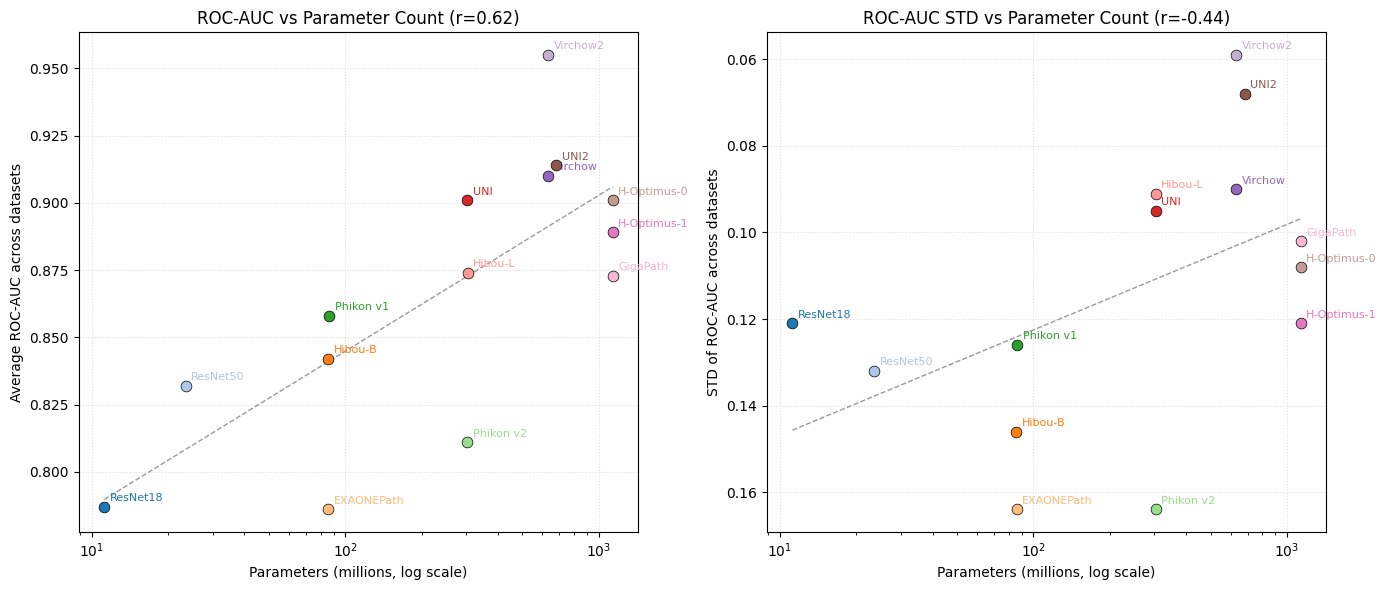

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from matplotlib.lines import Line2D

# ---- Input data ----
param_millions = {
    'ResNet18': 11.2,
    'ResNet50': 23.5,
    'H0-mini': 85.7,          # ignored
    'Hibou-B': 85.7,
    'EXAONEPath': 85.8,
    'Phikon v1': 86.4,
    'UNI': 303.4,
    'Phikon v2': 303.4,
    'Hibou-L': 303.7,
    'Virchow': 631.2,
    'Virchow2': 631.2,
    'UNI2': 681.4,
    'H-Optimus-0': 1134.8,
    'H-Optimus-1': 1134.8,
    'GigaPath': 1135.0,
}

avg_roc_auc = {
    'Virchow2': 0.955,
    'H-Optimus-0': 0.901,
    'Virchow': 0.910,
    'UNI2': 0.914,
    'Hibou-L': 0.874,
    'Hibou-B': 0.842,
    'UNI': 0.901,
    'H-Optimus-1': 0.889,
    'GigaPath': 0.873,
    'Phikon v1': 0.858,
    'Phikon v2': 0.811,
    'ResNet50': 0.832,
    'EXAONEPath': 0.786,
    'ResNet18': 0.787,
}

avg_std = {
    'Virchow2': 0.059,
    'H-Optimus-0': 0.108,
    'Virchow': 0.090,
    'UNI2': 0.068,
    'Hibou-L': 0.091,
    'Hibou-B': 0.146,
    'UNI': 0.095,
    'H-Optimus-1': 0.121,
    'GigaPath': 0.102,
    'Phikon v1': 0.126,
    'Phikon v2': 0.164,
    'ResNet50': 0.132,
    'EXAONEPath': 0.164,
    'ResNet18': 0.121,
}

# ---- Harmonize keys ----
models = sorted(set(avg_roc_auc.keys()).intersection(param_millions.keys()),
                key=lambda m: (param_millions[m], m))

# Arrays
x_params = np.array([param_millions[m] for m in models])
y_auc    = np.array([avg_roc_auc[m] for m in models])
y_std    = np.array([avg_std[m] for m in models])

# Pearson r
r_auc, _ = pearsonr(x_params, y_auc)
r_std, _ = pearsonr(x_params, y_std)

# Colors
cmap = plt.get_cmap('tab20')
colors = {m: cmap(i % 20) for i, m in enumerate(models)}

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Panel 1: ROC-AUC vs Params
ax = axes[0]
for m in models:
    ax.scatter(param_millions[m], avg_roc_auc[m], s=60, color=colors[m], edgecolor='k', linewidth=0.5, zorder=3)
    ax.annotate(m, (param_millions[m], avg_roc_auc[m]), textcoords="offset points", xytext=(4, 4), ha='left', fontsize=8, color=colors[m])

ax.set_xscale('log')
ax.set_xlabel('Parameters (millions, log scale)')
ax.set_ylabel('Average ROC-AUC across datasets')
ax.set_title(f'ROC-AUC vs Parameter Count (r={r_auc:.2f})')
ax.grid(True, linestyle=':', alpha=0.4)

# Trend line
logx = np.log10(x_params)
coef = np.polyfit(logx, y_auc, 1)
trend = np.poly1d(coef)(logx)
order = np.argsort(x_params)
ax.plot(x_params[order], trend[order], linestyle='--', linewidth=1, color='grey', alpha=0.8, zorder=2)

# Panel 2: STD vs Params
ax2 = axes[1]
for m in models:
    ax2.scatter(param_millions[m], avg_std[m], s=60, color=colors[m], edgecolor='k', linewidth=0.5, zorder=3)
    ax2.annotate(m, (param_millions[m], avg_std[m]), textcoords="offset points", xytext=(4, 4), ha='left', fontsize=8, color=colors[m])

coef = np.polyfit(logx, y_std, 1)
trend = np.poly1d(coef)(logx)
order = np.argsort(x_params)
ax2.plot(x_params[order], trend[order], linestyle='--', linewidth=1, color='grey', alpha=0.8, zorder=2)

ax2.set_xscale('log')
ax2.set_xlabel('Parameters (millions, log scale)')
ax2.set_ylabel('STD of ROC-AUC across datasets')
ax2.set_title(f'ROC-AUC STD vs Parameter Count (r={r_std:.2f})')
ax2.invert_yaxis()
ax2.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()